# 01 - Eksplorasi dan Pembersihan Data

**Tujuan:** Memahami dataset (distribusi, nilai kosong, long-tail) lalu membersihkannya menjadi tabel siap pakai.

| | |
|---|---|
| **Input** | `data/raw/MM-Food-100K.csv` (di dalam zip) |
| **Output** | `data/processed/clean.csv`, `reports/metrics/eda_stats.json`, grafik di `reports/figures/` |
| **Prasyarat** | Notebook 00 |

> Setiap notebook berdiri sendiri: ia membaca hasil notebook sebelumnya dari Google Drive, jadi sesi Colab boleh diputus/diulang di antara notebook.

In [1]:
# --- Bootstrap (sama di setiap notebook) ---------------------------------------
# 1) Sambungkan Google Drive (tempat semua hasil disimpan permanen)
import os, sys, zipfile
from google.colab import drive
drive.mount('/content/drive')

# 2) Lokasi di Drive: folder ini sekaligus ROOT proyek (zip dan semua hasil ada di sini)
ROOT_ON_DRIVE = "/content/drive/MyDrive/models-train/mmfood-multitask"
ZIP_ON_DRIVE = f"{ROOT_ON_DRIVE}/mmfood-multitask.zip"

# 3) Folder hasil = ROOT di Drive. Harus diset SEBELUM mengimpor config
os.environ["MMFOOD_PROJECT"] = ROOT_ON_DRIVE

# 4) Ekstrak kode + dataset dari zip ke disk lokal Colab (hanya sekali per sesi)
REPO = "/content/mmfood-multitask"
if not os.path.exists(REPO):
    with zipfile.ZipFile(ZIP_ON_DRIVE) as z:
        z.extractall("/content")

# 5) Daftarkan folder src/ agar modul proyek bisa di-import
sys.path.insert(0, f"{REPO}/src")

# 6) Muat path folder (P) dan konfigurasi (CFG) dari src/config.py
from config import get_paths, load_cfg
P = get_paths()       # P.processed, P.checkpoints, P.hf_export, ... (folder dibuat otomatis)
CFG = load_cfg(P)     # nilai bawaan + perubahan dari notebook 00
print("Folder hasil:", P.project)

Mounted at /content/drive
Folder hasil: /content/drive/MyDrive/models-train/mmfood-multitask


## Langkah 1.1 - Muat data mentah
Dataset berisi 100.000 baris. **Gambar tidak ada di CSV**, hanya URL-nya; gambar diunduh di notebook 02.

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Baca CSV mentah
raw = pd.read_csv(P.raw_csv)
print("Ukuran:", raw.shape)
raw.head(3).T   # transpose agar kolom mudah dibaca

Ukuran: (100000, 10)


,0,1,2
image_url,https://file.b18a.io/7843322356500104680_44354...,https://file.b18a.io/7833227147700100732_67487...,https://file.b18a.io/7832600581600103585_26423...
camera_or_phone_prob,0.7,0.7,0.8
food_prob,0.95,1.0,0.95
dish_name,Fried Chicken,Pho,Pan-fried Dumplings
food_type,Restaurant food,Restaurant food,Restaurant food
ingredients,"[""chicken"",""breading"",""oil""]","[""noodles"",""beef"",""basil"",""lime"",""green onions...","[""dumplings"",""chili oil"",""soy sauce""]"
portion_size,"[""chicken:300g""]","[""noodles:200g"",""beef:100g"",""vegetables:50g""]","[""dumplings:300g"",""sauce:50g""]"
nutritional_profile,"{""fat_g"":25.0,""protein_g"":30.0,""calories_kcal""...","{""fat_g"":15.0,""protein_g"":25.0,""calories_kcal""...","{""fat_g"":15.0,""protein_g"":20.0,""calories_kcal""..."
cooking_method,Frying,boiled,Pan-frying
sub_dt,20250704,20250702,20250625


## Langkah 1.2 - Cek kualitas data
Yang dicari: nilai kosong, jumlah nilai unik per kolom (kardinalitas), dan distribusi kelas. Ini menentukan strategi pembersihan.

In [3]:
# Nilai kosong per kolom
print("Nilai kosong:\n", raw.isna().sum())

# Kardinalitas: dish_name dan cooking_method punya terlalu banyak nilai unik untuk dijadikan kelas apa adanya
print("\nJumlah nilai unik dish_name      :", raw.dish_name.nunique())
print("Jumlah nilai unik cooking_method :", raw.cooking_method.nunique())

# Distribusi food_type (kelas 'Others' sangat sedikit -> perlu hati-hati)
print("\n", raw.food_type.value_counts())

Nilai kosong:
 image_url                  0
camera_or_phone_prob       0
food_prob                  0
dish_name                  2
food_type                  0
ingredients                0
portion_size               0
nutritional_profile        0
cooking_method          1358
sub_dt                     0
dtype: int64

Jumlah nilai unik dish_name      : 19288
Jumlah nilai unik cooking_method : 2264

 food_type
Homemade food                46555
Restaurant food              35461
Raw vegetables and fruits     9357
Packaged food                 8354
Others                         273
Name: count, dtype: int64


In [4]:
# 15 nama hidangan paling sering + contoh cooking_method yang tidak konsisten
print(raw.dish_name.value_counts().head(15))
print("\nContoh cooking_method (tulisan berbeda, arti sama):")
print(raw.cooking_method.value_counts().head(12))

dish_name
Noodle Soup             1960
Dumplings               1236
Hot Pot                  995
Stir-fried Noodles       796
Fried Chicken            712
Apple                    705
Watermelon               695
Fried Rice               612
Pizza                    609
Beef Noodle Soup         582
Lychee                   566
Mixed Asian Cuisine      530
Grilled Meat Skewers     520
Seafood Platter          420
Strawberries             400
Name: count, dtype: int64

Contoh cooking_method (tulisan berbeda, arti sama):
cooking_method
Raw            11598
boiling         7162
Fried           6286
Stir-frying     5887
stir-frying     5325
Baked           4186
boiled          4010
Grilling        3663
Baking          3045
stir-fried      2689
stewing         1807
braising        1695
Name: count, dtype: int64


## Langkah 1.3 - Pembersihan
Fungsi `prepare_dataframe` (di `src/data_utils.py`) melakukan:
1. Buang baris dengan `food_prob` rendah (kemungkinan bukan makanan).
2. Normalisasi `dish_name` (huruf kecil, rapikan spasi).
3. Normalisasi `cooking_method` ke ~10 kelompok dengan aturan kata kunci (`stir-frying`, `stir-fried` -> `stir-fry`).
4. Parse `nutritional_profile` (string JSON) menjadi 4 kolom angka; buang kalori <= 0.
5. Tandai `dish_label` hanya untuk Top-K nama teratas (sisanya kosong -> diabaikan loss dish).

In [5]:
from data_utils import prepare_dataframe, NUTRITION_KEYS

# Jalankan pembersihan memakai parameter dari CFG
clean = prepare_dataframe(P.raw_csv, top_k_dish=CFG["top_k_dish"], min_food_prob=CFG["min_food_prob"])
print("Baris sebelum:", len(raw), "-> sesudah:", len(clean))
print("Baris dengan label dish Top-K:", clean.dish_label.notna().sum(), "| jumlah kelas dish:", clean.dish_label.nunique())
print("\nMetode masak setelah normalisasi:\n", clean.cooking_norm.value_counts())

Baris sebelum: 100000 -> sesudah: 99949
Baris dengan label dish Top-K: 22514 | jumlah kelas dish: 50

Metode masak setelah normalisasi:
 cooking_norm
stir-fry       19012
boil           17486
raw            16362
fry            11703
bake           10099
grill           6378
other           5815
steam           5653
simmer-stew     5185
unknown         1342
pan-fry          882
deep-fry          32
Name: count, dtype: int64


## Langkah 1.4 - Visualisasi
Grafik disimpan ke `reports/figures/` supaya bisa dipakai di laporan.

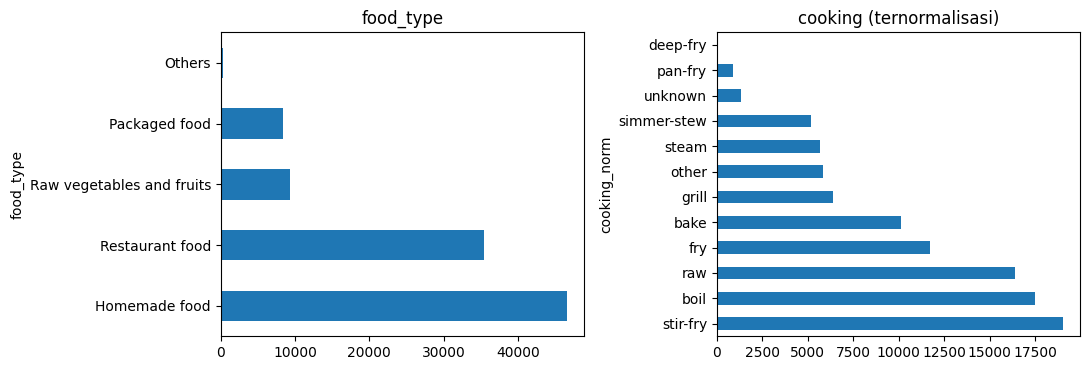

In [6]:
# Grafik 1: distribusi food_type dan metode masak
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
clean.food_type.value_counts().plot.barh(ax=ax[0], title="food_type")
clean.cooking_norm.value_counts().plot.barh(ax=ax[1], title="cooking (ternormalisasi)")
plt.tight_layout()
plt.savefig(f"{P.figures}/eda_label_distribution.png", dpi=130)
plt.show()

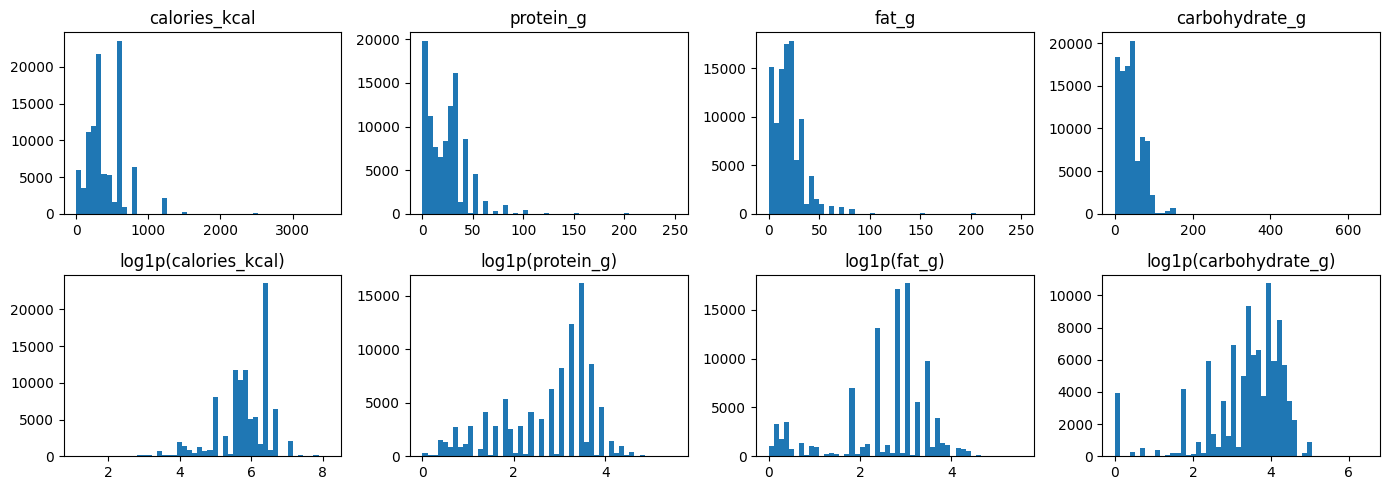

In [7]:
# Grafik 2: distribusi nutrisi. Condong ke kanan -> alasan memakai log1p di notebook 03
fig, ax = plt.subplots(2, 4, figsize=(14, 5))
for i, k in enumerate(NUTRITION_KEYS):
    ax[0, i].hist(clean[k], bins=50);               ax[0, i].set_title(k)
    ax[1, i].hist(np.log1p(clean[k]), bins=50);     ax[1, i].set_title("log1p(" + k + ")")
plt.tight_layout()
plt.savefig(f"{P.figures}/eda_nutrition_distribution.png", dpi=130)
plt.show()

## Langkah 1.5 - Simpan hasil

In [8]:
# Simpan tabel bersih untuk notebook 02
clean.to_csv(f"{P.processed}/clean.csv", index=False)

# Simpan ringkasan statistik untuk laporan
stats = {
    "rows_raw": int(len(raw)),
    "rows_clean": int(len(clean)),
    "unique_dish_raw": int(raw.dish_name.nunique()),
    "unique_cooking_raw": int(raw.cooking_method.nunique()),
    "food_type_counts": clean.food_type.value_counts().to_dict(),
    "cooking_counts": clean.cooking_norm.value_counts().to_dict(),
    "dish_labeled_rows": int(clean.dish_label.notna().sum()),
    "nutrition_describe": clean[NUTRITION_KEYS].describe().round(2).to_dict(),
}
json.dump(stats, open(f"{P.metrics}/eda_stats.json", "w"), indent=2)
print("Tersimpan:", f"{P.processed}/clean.csv")

Tersimpan: /content/drive/MyDrive/models-train/mmfood-multitask/data/processed/clean.csv
